# 03 · Semantic engine

**ECE ING5 NLP project: semantic book recommendation (GenderBook)**

This notebook documents part **P3: turning text into vectors and measuring closeness of meaning**. It is the building block used by the enrichment (P2), the scoring (P4), the application (P5) and the evaluation (P6).

| Module | Role |
|---|---|
| `src/preprocessing.py` | minimal cleaning (SBERT) / bag-of-words preparation (TF-IDF, GloVe) / sentence splitting |
| `src/embeddings.py` | `EmbeddingEngine`: `encode`, `book_matrix` (disk cache), `label_matrix`, `search`, `best_sentence` |
| `src/encoders.py` | TF-IDF and GloVe baselines, `get_encoder()` (for P6), `compare_encoders()` |
| `src/semantic_map.py` | cosine distribution, 2D UMAP map, query projection, genre-level measures |

**Outline**
1. Environment setup
2. Preprocessing: why two different cleanings
3. Three ways to represent a text, and the choice of cosine similarity
4. The `EmbeddingEngine`
5. Long texts: truncation or chunking?
6. Semantic vs keyword matching: TF-IDF vs GloVe vs SBERT
7. MiniLM vs MPNet
8. Famous books in the full 12,000-book catalogue
9. Cosine distribution and calibration
10. Semantic map and genres
11. Computation time
12. Interface for the team
13. Limitations and conclusions

> **How to run.** The notebook reuses the caches in `data/embeddings/` and the results in `docs/figures/`
> produced by the `scripts/p3_*.py` scripts, so it runs in a few minutes. To recompute everything:
> `p3_build_embeddings` (≈ 7 min), `p3_compare_encoders` (≈ 3 min, + ≈ 4 min with `--mpnet`), `p3_semantic_map` (≈ 2 min).

## 1. Environment setup

We move to the repository root so that `src/` can be imported (the notebook is launched from `notebooks/`).

In [1]:
# Step 1: move to the repository root (the folder that contains src/)
import os
import sys
import time
from pathlib import Path

ROOT = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
os.chdir(ROOT)
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

# Step 2: analysis libraries
import json
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image, display

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_colwidth", 80, "display.width", 160)

# Step 3: the team's modules
from src import config
from src.embeddings import EmbeddingEngine, cosine_sim, l2_normalize
from src.preprocessing import preprocess_for_classic, preprocess_for_transformer, split_sentences

FIG = config.FIGURES_DIR
FIG.mkdir(parents=True, exist_ok=True)
print("Repository root:", ROOT)
print("Python in use  :", sys.executable)   # should point to .venv (otherwise: wrong Jupyter kernel)

Repository root: C:\Users\mleon\Documents\GenderBook-Projet-NLP
Python in use  : C:\Users\mleon\Documents\GenderBook-Projet-NLP\.venv\Scripts\python.exe


## 2. Preprocessing: why two different cleanings

The models do not have the same needs:

* **SBERT (contextual)** reads the whole sentence: "empty" words (*not, no, without*) and punctuation **carry meaning**. The cleaning is therefore **minimal** (leftover HTML, whitespace, typographic quotes, repeated punctuation).
* **TF-IDF and GloVe (bag of words)** ignore word order: very frequent words drown the signal and variants of the same word must be merged. We apply **lowercasing, stopword and punctuation removal, and spaCy lemmatisation**.
* `split_sentences` splits a blurb into sentences for **explainability** (the sentence of the blurb that is closest to the user's request).

A deliberately tricky example: a negation.

In [2]:
# A sentence with HTML, an HTML entity, a negation and repeated punctuation
text = ("A boy discovers he is a <i>wizard</i> &amp; goes to a magic school. "
        "He is NOT happy at first!!! Dr. Smith helps him.")

print("For SBERT  :", preprocess_for_transformer(text))
print("For TF-IDF :", preprocess_for_classic(text))
print("Sentences  :", split_sentences(text))

For SBERT  : A boy discovers he is a wizard & goes to a magic school. He is NOT happy at first! Dr. Smith helps him.


For TF-IDF : boy discover wizard magic school happy dr smith help
Sentences  : ['A boy discovers he is a wizard & goes to a magic school.', 'He is NOT happy at first!', 'Dr. Smith helps him.']


**Takeaway.** In the bag-of-words version, **"NOT" has disappeared** (it is a stopword): for TF-IDF, *"NOT happy"* and *"happy"* become identical. This is why the text sent to SBERT is barely preprocessed. The sentence splitter does not break after "Dr.".

## 3. Three ways to represent a text, and the choice of cosine similarity

| Representation | Principle | Synonyms? | Context? |
|---|---|---|---|
| **TF-IDF** (lexical) | a text = sparse vector of its words, weighted by TF (frequency in the text) × IDF (rarity in the catalogue) | no | no |
| **GloVe** (*static* word embeddings) | a word = one vector learned on Wikipedia (co-occurrences); a text = average of its words | yes | no: a word has **a single** vector ("bank" of a river = "bank" for money), and averaging loses word order and negations |
| **SBERT** (*contextual* embeddings) | a transformer reads the whole sentence; it is fine-tuned so that two sentences with the same meaning get close vectors | yes | **yes** |

**Chosen model: `all-MiniLM-L6-v2`** (384 dimensions, fast on CPU, the reference model of the project brief), compared with `all-mpnet-base-v2` (768 dimensions) in section 7.

**Why cosine similarity?**
* It measures the **angle** between two vectors, regardless of their length: a long blurb and a short blurb on the same topic stay close.
* It is the measure SBERT is trained with.
* All our vectors are **normalised** (norm 1). Then `cos(a, b) = a · b` and the Euclidean distance satisfies `‖a − b‖² = 2 − 2·cos(a, b)`: **both measures give exactly the same ranking**. Cosine has the advantage of being computed for 12,000 books with **a single matrix-vector product**.

Numerical check on real vectors:

In [3]:
# Step 1: the engine (MiniLM by default, full catalogue through P1's load_books)
engine = EmbeddingEngine()
books = engine.books
M = engine.book_matrix(show_progress=False)          # reloaded from the disk cache
print(f"Catalogue: {M.shape[0]} books, vectors of dimension {M.shape[1]}")
print(f"Vector norms: min {np.linalg.norm(M, axis=1).min():.4f}, max {np.linalg.norm(M, axis=1).max():.4f}")

# Step 2: cosine and Euclidean distance for one query -> same ranking?
q = engine.encode(["a boy discovers he is a wizard and goes to a school of magic"])[0]
cos = M @ q
eucl = np.linalg.norm(M - q, axis=1)
print("‖a − b‖² = 2 − 2·cos holds:", np.allclose(eucl ** 2, 2 - 2 * cos, atol=1e-4))
print("Same top 10 (decreasing cosine = increasing distance):",
      np.array_equal(np.argsort(-cos)[:10], np.argsort(eucl)[:10]))

Catalogue: 12000 books, vectors of dimension 384
Vector norms: min 1.0000, max 1.0000


Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

‖a − b‖² = 2 − 2·cos holds: True
Same top 10 (decreasing cosine = increasing distance): True


## 4. The `EmbeddingEngine`

Interface agreed by the team:

| Method | Role | Used by |
|---|---|---|
| `encode(texts)` | minimal cleaning → SBERT → normalised vectors | everyone |
| `book_matrix()` | (N, d) matrix of the books, **encoded once** then reloaded from `data/embeddings/` | P4, P5 |
| `label_matrix(block)` | vectors of the `blocks.json` labels (reuses P2's `encode_blocks`: themes v2 = average of 4 sentences) | P4 |
| `search(q, k)` | the k closest books (`argpartition`: O(N)) | P4, P6 |
| `best_sentence(q, text)` | the sentence of the blurb that is closest to the query | P4, P5 |

**Guaranteed alignment.** The cache stores the matrix **and** the list of `book_id` in the same order. If the catalogue changes (regenerated by P1 or P2), the identifiers no longer match and the engine re-encodes instead of mixing up books (tested in `tests/test_embeddings.py`).

In [4]:
# Cache metadata (traceability: model, date, encoding time)
meta_path = engine._cache_paths()[2]
print(json.dumps(json.loads(meta_path.read_text(encoding="utf-8")), indent=2))

# Search + explanation for a natural-language query
idx, scores = engine.search(q, k=5)
rows = []
for i, s in zip(idx, scores):
    sentence, s_sentence = engine.best_sentence(q, books.iloc[i]["description"])
    rows.append({"title": books.iloc[i]["title"][:45], "cosine": round(float(s), 3),
                 "closest sentence": sentence[:90], "sentence sim.": round(s_sentence, 2)})
pd.DataFrame(rows)

{
  "model": "sentence-transformers/all-MiniLM-L6-v2",
  "long_text": "truncate",
  "n_books": 12000,
  "dim": 384,
  "encode_seconds": 420.8,
  "created": "2026-11-24 10:50:11"
}


,title,cosine,closest sentence,sentence sim.
0,The Witch Boy,0.543,"When a mysterious danger threatens the other boys, Aster knows he can help -...",0.48
1,Magyk,0.488,An ExtraOrdinary Wizard mysteriously resigns from his post.,0.48
2,Magician,0.485,"At Crydee, a frontier outpost in the tranquil Kingdom of the Isles, an orpha...",0.39
3,Magic for Beginners,0.484,"Perfect for readers of George Saunders, Karen Russell, Neil Gaiman, and Aime...",0.48
4,Magician : Master,0.459,"Once he was an orphan called Pug, apprenticed to a sorcerer of the enchanted...",0.32


In [5]:
# Labels of the 4 blocks (vectors identical to P2's)
for block in config.BLOCKS:
    labels, L = engine.label_matrix(block)
    print(f"{block:<10}: {len(labels):>2} labels -> matrix {L.shape}")

# Zero-shot example: which themes are closest to the query?
labels, L = engine.label_matrix("Themes")
sims = L @ q
print("\nThemes closest to the query:",
      [(labels[j], round(float(sims[j]), 2)) for j in np.argsort(-sims)[:3]])

Genre     : 21 labels -> matrix (21, 384)
Themes    : 20 labels -> matrix (20, 384)
Style     : 10 labels -> matrix (10, 384)
Atmosphere: 15 labels -> matrix (15, 384)

Themes closest to the query: [('Coming of age', 0.39), ('Identity & self-discovery', 0.28), ('Adventure & exploration', 0.23)]


## 5. Long texts: truncation or chunking?

MiniLM only reads **256 tokens** (254 without `[CLS]`/`[SEP]`): the rest is silently ignored. The engine implements two strategies:
* `long_text="truncate"` (default): the model cuts the text;
* `long_text="chunks"`: the blurb is split into chunks of **complete sentences** that fit the limit, each chunk is encoded, and the (renormalised) average of the vectors is used.

Tokens per blurb: median 178, p95 308, max 419
19.5 % of the blurbs exceed 254 tokens


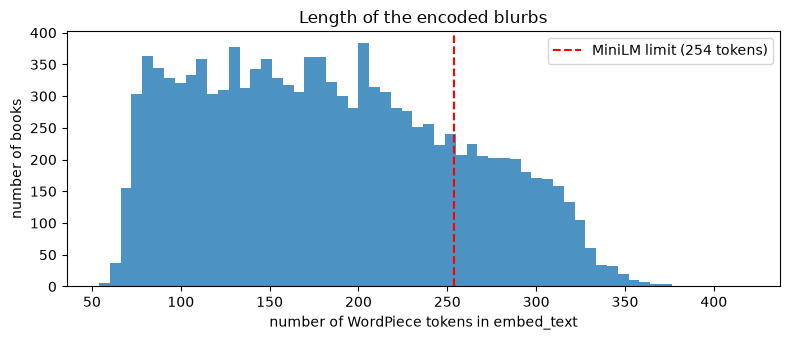

In [6]:
# Step 1: how many blurbs exceed the limit?
n_tok = engine.count_tokens(books["embed_text"].fillna("").tolist())
limit = engine.max_tokens - 2
print(f"Tokens per blurb: median {np.median(n_tok):.0f}, p95 {np.percentile(n_tok, 95):.0f}, max {n_tok.max()}")
print(f"{100 * (n_tok > limit).mean():.1f} % of the blurbs exceed {limit} tokens")

fig, ax = plt.subplots(figsize=(8, 3.5))
ax.hist(n_tok, bins=60, color="tab:blue", alpha=0.8)
ax.axvline(limit, color="red", linestyle="--", label=f"MiniLM limit ({limit} tokens)")
ax.set_xlabel("number of WordPiece tokens in embed_text")
ax.set_ylabel("number of books")
ax.set_title("Length of the encoded blurbs")
ax.legend()
fig.tight_layout()
fig.savefig(FIG / "p3_token_lengths.png", dpi=150)
plt.show()

In [7]:
# Step 2: comparison on paraphrased "famous book" queries (rank of the expected book among 12,000)
from scripts.p3_build_embeddings import FAMOUS_QUERIES, rank_of_expected

def famous_ranks(eng):
    # Rank of the expected book for each famous query with a given engine.
    # Rows are keyed by the QUERY (not by the matched title): the best-ranked edition of a book
    # can differ between engines (e.g. two "The Hobbit" titles in the catalogue).
    mat, titles, out = eng.book_matrix(show_progress=False), eng.books["title"].fillna(""), {}
    for query, pattern in FAMOUS_QUERIES:
        rank, _ = rank_of_expected(mat @ eng.encode([query])[0], titles, pattern)
        out[query[:45] + "…"] = rank
    return pd.Series(out, dtype="float")

chunks_engine = EmbeddingEngine(long_text="chunks", books=books, model=engine.model)
if chunks_engine._cache_paths()[0].exists():
    comp = pd.DataFrame({"truncation": famous_ranks(engine), "chunks": famous_ranks(chunks_engine)})
    found = comp.dropna()          # queries whose expected book is in the catalogue
    summary = pd.DataFrame({c: {"top 10": int((found[c] <= 10).sum()), "MRR": round(float((1 / found[c]).mean()), 3)}
                            for c in comp}).T
    display(comp)
    display(summary)
else:
    print("No 'chunks' cache: run `python -X utf8 -m scripts.p3_build_embeddings --long-text chunks` (≈ 9 min).")

,truncation,chunks
a boy discovers he is a wizard and goes to a …,32.0,32.0
a teenage girl volunteers to take her sister'…,5.0,4.0
a small hairy-footed creature leaves his comf…,8.0,15.0
an obsessed sea captain hunts the white whale…,NaN,NaN
a witty young woman in Regency England clashe…,570.0,111.0
a totalitarian state spies on its citizens an…,2.0,3.0
a scientist builds a living creature from dea…,27.0,32.0


,top 10,MRR
truncation,3.0,0.149
chunks,2.0,0.120


**Decision: we keep truncation.**
* No overall gain on our queries (top 10 and MRR equal or slightly better with truncation), for a **+26 %** encoding time (8 min 49 s vs 7 min).
* Publishers put the **hook at the beginning** of the blurb; the end mostly contains praise and edition details.
* Averaging chunks **dilutes** the meaning when one chunk tells the story and another one praises the book.
* Notable exception: *Pride and Prejudice* ranks much higher with chunking (the end of its blurb describes more of the story).

*Caveat: 6 queries are not enough for a statistical conclusion; the conclusion is "no gain observed, at a higher cost".*

## 6. Semantic vs keyword matching: TF-IDF vs GloVe vs SBERT

**Protocol.** 7 queries, each describing one specific book of the sample (500 books) **without any word in common** with its blurb after lemmatisation (checked automatically). For each method we measure the **rank** of the expected book (1 = found first; ≈ 250 = random) and the **MRR** (*Mean Reciprocal Rank*: average of 1/rank, 1 = always first).

Results produced by `python -X utf8 -m scripts.p3_compare_encoders` (file `docs/figures/p3_encoder_comparison_sample.csv`):

,paraphrased query,expected book_id
0,a parentless lad learns spells from an old wizard while creatures from anoth...,9780586217832
1,the celebrated pipe-smoking sleuth tracks a serial murderer of prostitutes i...,9781416583318
2,mariners whose vessel sank are seized as captives by Bedouin tribes and marc...,9780316159357
3,a chatty ginger-haired adopted child with a vivid fancy changes the lives of...,9781442490017
4,a Greek comic play from two thousand years ago showing what wives and mother...,9780198144960
5,an illustrated retelling where a bloodsucking aristocrat from the Carpathian...,9780785149064
6,an antimilitarist comic tale mocking the Habsburg monarchy through a naive a...,9781857151510


encoder,tfidf,glove,glove-tfidf,minilm
target,,,,
Anne of Green Gables,369.0,33.0,9.0,5.0
Dracula,296.5,55.0,69.0,32.0
Dust and Shadow,310.5,14.0,16.0,3.0
Lysistrata,356.5,352.0,271.0,1.0
Magician,305.5,20.0,5.0,1.0
Skeletons on the Zahara : A True Story of Survival,256.5,3.0,3.0,1.0
The Good Soldier Svejk,286.0,1.0,1.0,4.0


encoder,tfidf,glove,glove-tfidf,minilm
mean rank,311.5,68.29,53.43,6.71
median rank,305.5,20.00,9.00,3.00
top-1,0.0,1.00,1.00,3.00
top-10,0.0,2.00,4.00,6.00
MRR,0.0,0.22,0.25,0.54


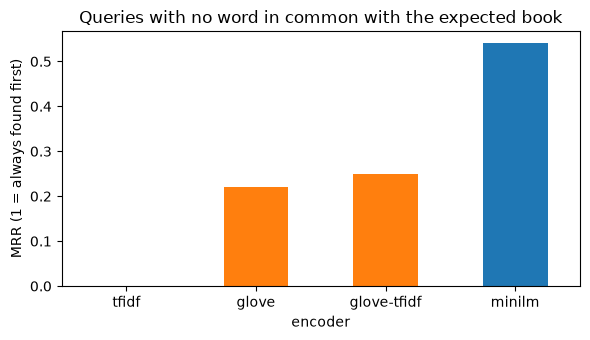

In [8]:
from scripts.p3_compare_encoders import QUERIES

# The queries (the words deliberately avoided are listed in the script)
display(pd.DataFrame(QUERIES, columns=["paraphrased query", "expected book_id"]))

res = pd.read_csv(FIG / "p3_encoder_comparison_sample.csv")
order = [e for e in ["tfidf", "glove", "glove-tfidf", "minilm", "mpnet"] if e in res["encoder"].unique()]
ranks = res.pivot(index="target", columns="encoder", values="rank")[order]
display(ranks)

def summarize(r):
    # Rank indicators: mean and median rank, top-1, top-10, MRR
    return pd.DataFrame({"mean rank": r.mean(), "median rank": r.median(),
                         "top-1": (r == 1).sum(), "top-10": (r <= 10).sum(), "MRR": (1 / r).mean()}).T.round(2)
summary_enc = summarize(ranks)
display(summary_enc)

fig, ax = plt.subplots(figsize=(6, 3.5))
summary_enc.loc["MRR"].plot.bar(ax=ax, color=["lightgrey", "tab:orange", "tab:orange", "tab:blue"][:len(order)])
ax.set_ylabel("MRR (1 = always found first)")
ax.set_title("Queries with no word in common with the expected book")
ax.set_xticklabels(ax.get_xticklabels(), rotation=0)
fig.tight_layout()
fig.savefig(FIG / "p3_encoder_mrr.png", dpi=150)
plt.show()

**Reading.**
1. **TF-IDF finds nothing** (MRR 0, mean rank worse than random): with no shared word, the similarity is zero. This shows that *keyword matching* is not enough.
2. **GloVe understands synonyms** (mean rank ≈ 68); IDF weighting helps a little (≈ 53) because rare words are more informative.
3. **SBERT understands context**: 6 books out of 7 in the top 10, MRR 0.54.

**Examples to remember.**
* *Lysistrata*: GloVe 352nd, **SBERT 1st**. The query only contains common words; their average says nothing, the meaning of the sentence does.
* *Magician*: TF-IDF 305th → GloVe 20th → **SBERT 1st**.
* *The Good Soldier Svejk*: **GloVe 1st**, SBERT 4th. On a rare proper noun ("Habsburg"), word vectors learned on Wikipedia are very effective: SBERT is not better everywhere.

*Cost: GloVe is slow here (≈ 65 s) because of spaCy lemmatisation, not because of GloVe itself; SBERT (≈ 27 s) needs no heavy preprocessing.*

## 7. MiniLM vs MPNet

Same protocol with `all-mpnet-base-v2` (768 dimensions, 110 M parameters vs 22 M):

In [9]:
mp_path = FIG / "p3_encoder_comparison_sample_minilm-mpnet.csv"
if mp_path.exists():
    mp = pd.read_csv(mp_path)
    mp_ranks = mp.pivot(index="target", columns="encoder", values="rank")[["minilm", "mpnet"]]
    display(mp_ranks)
    display(summarize(mp_ranks))
    display(mp.groupby("encoder")["seconds"].first().rename("seconds (500 books)").to_frame())
else:
    print("Run `python -X utf8 -m scripts.p3_compare_encoders --only minilm mpnet`.")

encoder,minilm,mpnet
target,,
Anne of Green Gables,5,52
Dracula,32,2
Dust and Shadow,3,1
Lysistrata,1,1
Magician,1,1
Skeletons on the Zahara : A True Story of Survival,1,1
The Good Soldier Svejk,4,1


encoder,minilm,mpnet
mean rank,6.71,8.43
median rank,3.00,1.00
top-1,3.00,5.00
top-10,6.00,6.00
MRR,0.54,0.79


,seconds (500 books)
encoder,
minilm,25.80
mpnet,185.31


**Reading.** MPNet finds the right book first **5 times out of 7** vs 3 (MRR **0.79** vs 0.54) and fixes MiniLM's failures (*Dracula* 32nd → 2nd: "*bloodsucking aristocrat from the Carpathians*" is understood as a vampire). Its **mean rank** is nevertheless worse (8.4 vs 6.7) because of **a single** case (*Anne of Green Gables*, 5th → 52nd): the mean is sensitive to outliers, hence the use of the **median** and the **MRR**.

**Cost:** MPNet is **≈ 8 times slower** on CPU (≈ 80 min to encode the 12,000 books vs 7 min; a few minutes on a GPU).

**Decision:** MiniLM remains the default model (responsive application, consistency with P2's enrichment and P4's calibration). Switching to MPNet is a team decision to be taken with P6's evaluation; the engine supports it without code changes (`EmbeddingEngine("mpnet")`). Results are **reproducible**: two runs give exactly the same ranks.

## 8. Famous books in the full 12,000-book catalogue

The full catalogue has 24 times more "competitors". The queries describe well-known books without naming the title, the characters or the author.

In [10]:
rows = []
for query, pattern in FAMOUS_QUERIES:
    qv = engine.encode([query])[0]
    sc = M @ qv
    rank, found = rank_of_expected(sc, books["title"].fillna(""), pattern)
    top3 = [books.iloc[i]["title"][:30] for i in np.argsort(-sc)[:3]]
    rows.append({"query": query[:60] + "…", "expected book": found[:30] or "(not in the catalogue)",
                 "rank / 12,000": rank, "top 3 returned": " | ".join(top3)})
famous = pd.DataFrame(rows)
famous

,query,expected book,"rank / 12,000",top 3 returned
0,a boy discovers he is a wizard and goes to a school of magic…,Harry Potter and the Goblet of,32.0,The Witch Boy | Magyk | Magician
1,a teenage girl volunteers to take her sister's place in a te…,The Hunger Games,5.0,My Fight Your Fight | Sisters | 4th of July
2,a small hairy-footed creature leaves his comfortable home to…,The Hobbit : Or There and Back,8.0,"The Fork, the Witch, and the W | Growth of the Soil | My Father's Dragon"
3,an obsessed sea captain hunts the white whale that took his …,(not in the catalogue),NaN,Sea Wolf | In the Heart of the Sea : The | Beneath the Surface : Killer W
4,a witty young woman in Regency England clashes with a proud …,Pride and Prejudice,570.0,The Luckiest Lady in London | How to Woo A Reluctant Lady | Elizabeth
5,a totalitarian state spies on its citizens and constantly re…,1984 Nineteen-Eighty Four,2.0,The Billion Dollar Spy : A Tru | 1984 Nineteen-Eighty Four | Fourth Protocol
6,a scientist builds a living creature from dead body parts an…,Frankenstein,27.0,The Chemistry of Death : (Davi | Death's Acre : Inside the Lege | Will My Ca...


**Reading.** The exact book is rarely first, but the books ranked above it are often **relevant** (*The Witch Boy*, *Magyk*, *Magician* for "a boy wizard"; *Sea Wolf* and *In the Heart of the Sea* for Moby Dick, which is not in the catalogue). For a **recommender**, this is what matters.

The failures mostly come **from the data**. Here is what the model actually "sees" for books that rank poorly:

In [11]:
for title in ["Pride and Prejudice", "Harry Potter and the Prisoner of Azkaban", "Harry Potter and the Sorcerer's Stone"]:
    hit = books[books["title"] == title]
    if len(hit):
        print(f"### {title}\n{hit.iloc[0]['embed_text'][:400]}…\n")

### Pride and Prejudice
Pride and Prejudice. One of the most universally loved and admired English novels, Pride and Prejudice was penned as a popular entertainment. But the consummate artistry of Jane Austen (1775-1817) transformed this effervescent tale of rural romance into a witty, shrewdly observed satire of English country life that is now regarded as one of the principal treasures of English language. In a remote …

### Harry Potter and the Prisoner of Azkaban
Harry Potter and the Prisoner of Azkaban. Jim Kay's dazzling depiction of J.K. Rowling's wizarding world has won legions of fans since the first Illustrated Edition of the Harry Potter novels was published in hardback in 2015, becoming a bestseller around the world. This irresistible smaller-format paperback edition of Harry Potter and the Prisoner of Azkaban perfectly pairs J.K. Rowling's storyte…

### Harry Potter and the Sorcerer's Stone
Harry Potter and the Sorcerer's Stone. Harry Potter has never been the star of a Qu

* *Pride and Prejudice*: the blurb is **publisher praise** and does not tell the story (no Elizabeth, no Darcy) → 570th. **No model** can retrieve a plot that is absent from the text.
* *Prisoner of Azkaban*: the blurb describes **the illustrated edition**, not the novel.
* *Sorcerer's Stone*: the blurb opens with **a series of negations** ("*He knows no spells, has never helped to hatch a dragon…*"); embeddings handle negation poorly.

**Consequence for P4:** a book ranked beyond 300th by the global similarity never enters the *retrieval* candidates, even with a perfect profile. Hence the value of the block scores (genres, themes), which depend less on the blurb alone.

## 9. Cosine distribution and calibration

Raw SBERT cosines are **compressed**: even a very good book rarely exceeds 0.5. To display a readable score, P4 recalibrates: `s̃ = clip((s − p5) / (p95 − p5), 0, 1)`. **On which population should p5 and p95 be computed?**

,p5,p50,p95,max,min
whole catalogue,-0.0235,0.1127,0.2708,0.5778,NaN
300 candidates,0.2662,0.3283,0.4096,NaN,0.2427


Share of candidates above the catalogue p95 (query by query): 100.0 %
'Catalogue' calibration: 93 % of the candidates get a score of 1.00
'Candidates' calibration: scores spread from 0.00 to 1.00 (standard deviation 0.27)


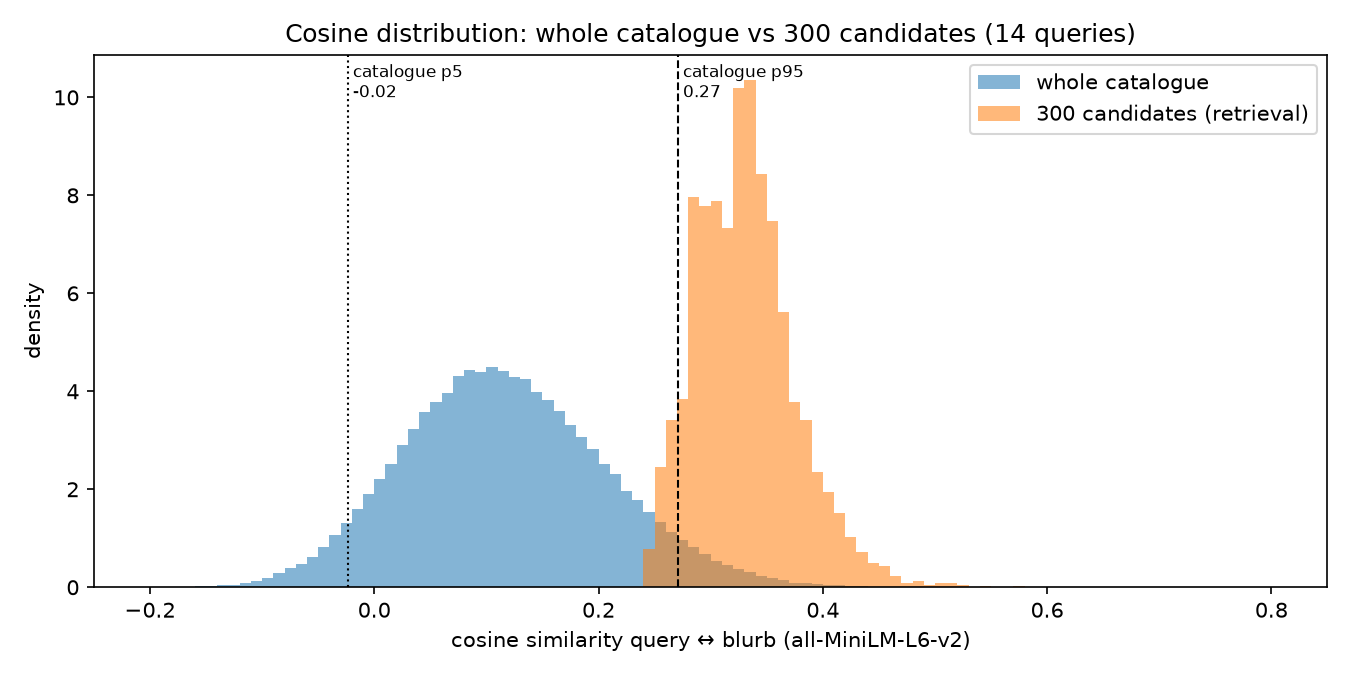

In [12]:
from scripts.p3_compare_encoders import QUERIES as TRAP_QUERIES
from src.semantic_map import cosine_distribution

queries = [qq for qq, _ in FAMOUS_QUERIES] + [qq for qq, _ in TRAP_QUERIES]
dist = cosine_distribution(M, engine.encode(queries))
display(pd.DataFrame({"whole catalogue": dist["catalogue"], f"{dist['top_k']} candidates": dist["candidates"]}).T)
print(f"Share of candidates above the catalogue p95 (query by query): "
      f"{100 * dist['share_candidates_above_catalogue_p95']:.1f} %")

# What would a calibration on the whole catalogue give, applied to the candidates?
lo, hi = dist["catalogue"]["p5"], dist["catalogue"]["p95"]
calibrated = np.clip((dist["_top_scores"] - lo) / (hi - lo), 0, 1)
print(f"'Catalogue' calibration: {100 * (calibrated >= 0.999).mean():.0f} % of the candidates get a score of 1.00")
lo_c, hi_c = dist["candidates"]["p5"], dist["candidates"]["p95"]
calibrated_c = np.clip((dist["_top_scores"] - lo_c) / (hi_c - lo_c), 0, 1)
print(f"'Candidates' calibration: scores spread from {calibrated_c.min():.2f} to {calibrated_c.max():.2f} "
      f"(standard deviation {calibrated_c.std():.2f})")

display(Image(str(FIG / "p3_cosine_distribution.png")))

**Reading.** The 300 candidates are **all** above the catalogue p95. A calibration on the whole catalogue would crush almost all of them to 1.00: the `S_desc` term would no longer separate anything. This is **P4's** argument; P4 calibrates on the candidates of reference personas (`calibration_p4.json`). This analysis is its **quantitative justification**; P3 therefore does not produce a competing `calibration.json` (team decision).

## 10. Semantic map and genres

**UMAP** projects the 12,000 vectors (384 dimensions) onto a plane while preserving neighbourhoods (cosine distance, `n_neighbors=15`, `min_dist=0.1`, fixed seed and frozen algorithm for reproducibility). The map is saved in `data/embeddings/umap_2d.npy` for the **similarity map of the application (P5)**; `project_query` places the user's point among their closest books.

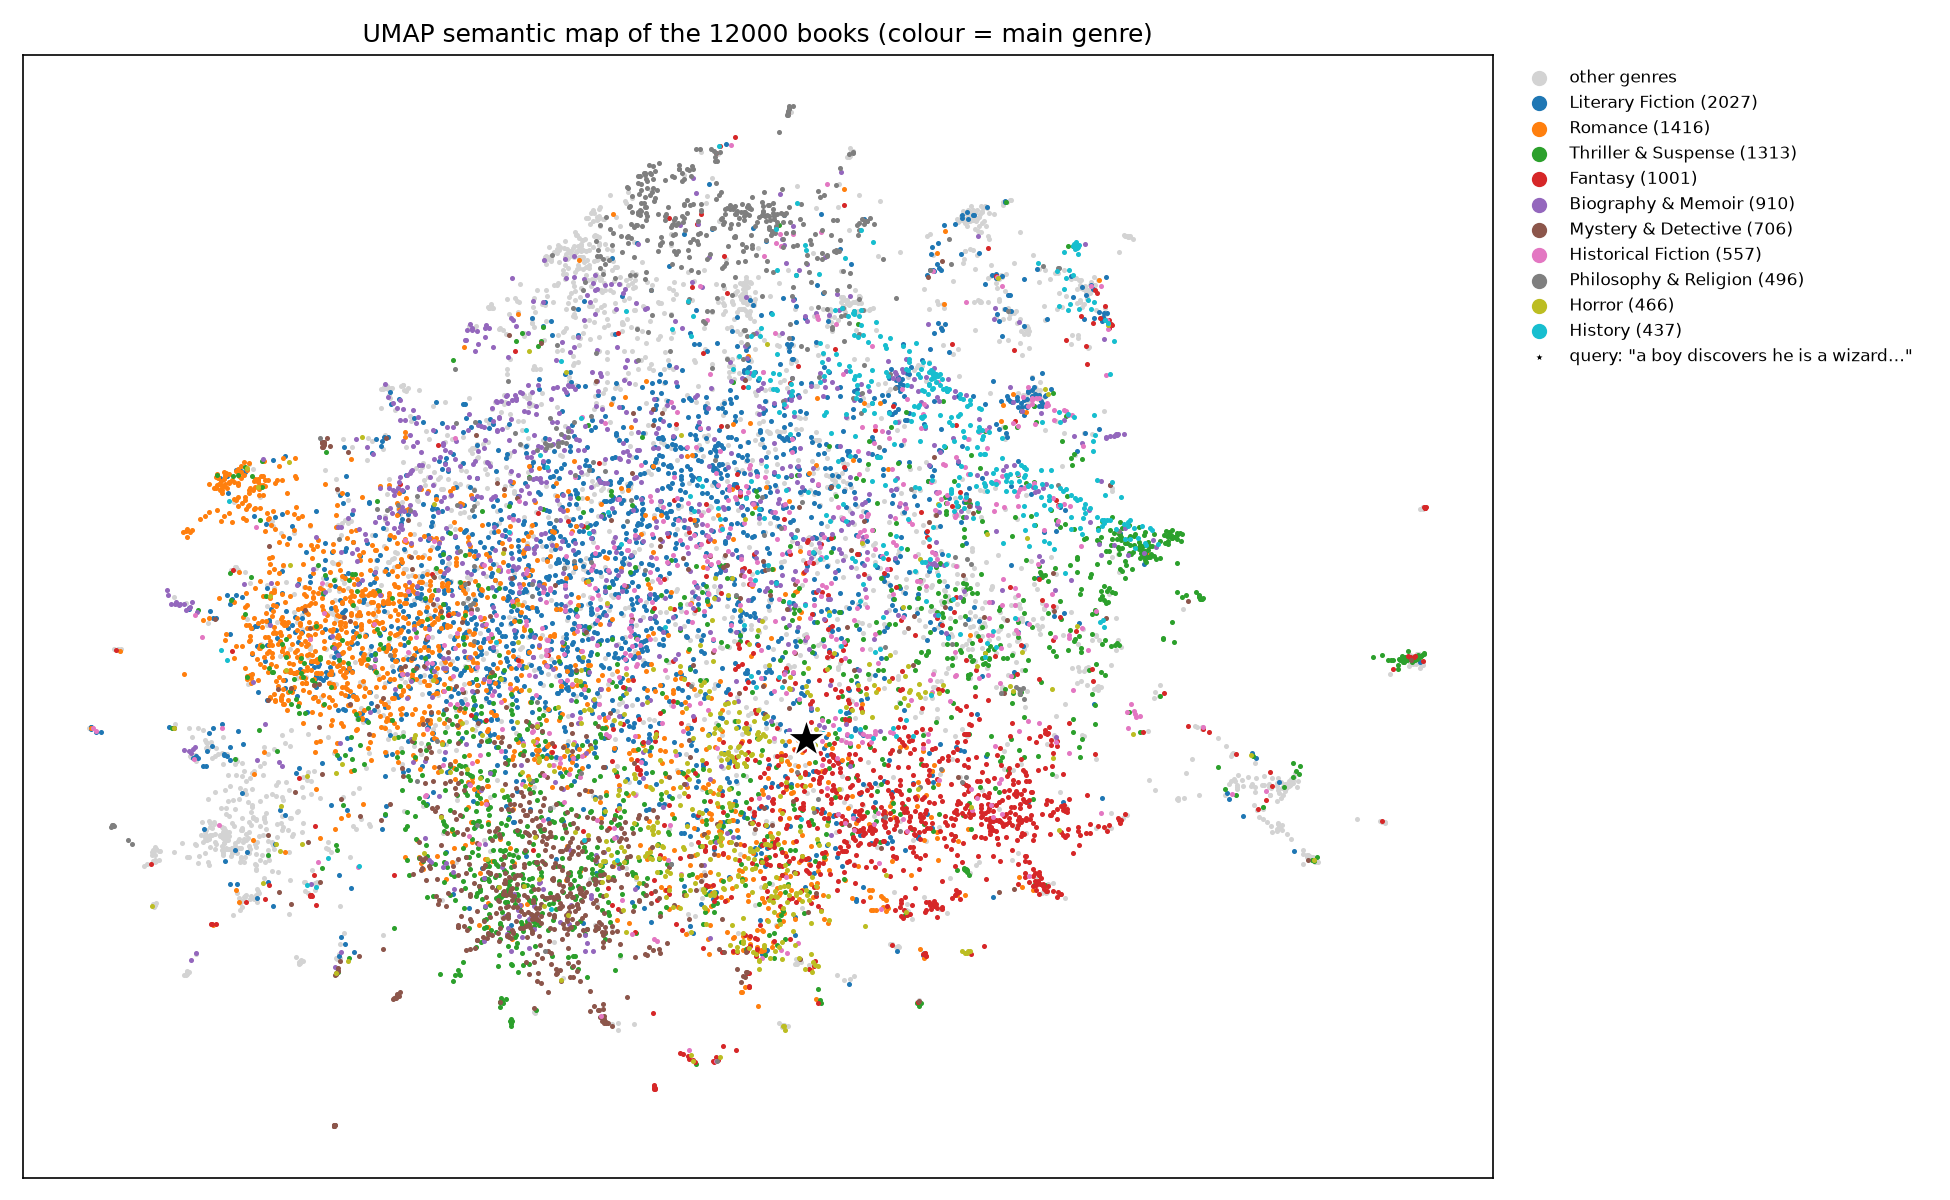

In [13]:
display(Image(str(FIG / "p3_umap_genres.png")))

**Reading the map.** Genres occupy **regions**: Romance (left), Fantasy (bottom right), Mystery and Thriller mixed together (bottom), Horror between Fantasy and crime, non-fiction at the top (History, Philosophy & Religion, Biography). Literary Fiction is spread out: it is more a **style** than a subject. The "boy wizard" query lands on the edge of the Fantasy region.

**Measures.** The silhouette score is close to 0 even though the map shows regions: silhouette requires clear-cut boundaries, whereas genres **overlap** (a book has up to 3 genres; some "genres" are audiences, such as Young Adult). A better-suited measure is **the share of the 10 nearest neighbours that share at least one genre**, compared with chance. To compare genres with each other, we divide by the chance rate **of each genre** (a frequent genre such as Literary Fiction mechanically has more neighbours "of the same genre").

In [14]:
from src.semantic_map import genre_silhouette

# Binary books x genres matrix (all genres assigned by P2)
genre_lists = [list(g) if g is not None else [] for g in books["genres"]]
all_genres = sorted({g for gl in genre_lists for g in gl})
G = np.zeros((len(books), len(all_genres)), dtype=np.float32)
for i, gl in enumerate(genre_lists):
    for g in gl:
        G[i, all_genres.index(g)] = 1

# Sample of books and their 10 nearest neighbours (excluding themselves)
rng = np.random.default_rng(config.RANDOM_SEED)
with_genre = np.flatnonzero(G.sum(1) > 0)
sample = rng.choice(with_genre, min(2000, len(with_genre)), replace=False)
S = M[sample] @ M.T
S[np.arange(len(sample)), sample] = -np.inf
nn = np.argpartition(-S, 10, axis=1)[:, :10]

# Share of neighbours sharing at least one genre, and EXACT expected share by chance (whole catalogue)
share_nn = np.array([((G[nn[r]] @ G[i]) > 0).mean() for r, i in enumerate(sample)])
share_rand = ((G[sample] @ G.T) > 0).mean(axis=1)
print(f"10 nearest neighbours: {100 * share_nn.mean():.1f} % share at least one genre")
print(f"Expected by chance   : {100 * share_rand.mean():.1f} %  ->  x{share_nn.mean() / share_rand.mean():.1f}")
print(f"Silhouette (main genre): {genre_silhouette(M, [gl[0] if gl else 'Unknown' for gl in genre_lists]):.3f}")

# Per genre: share among neighbours / share expected by chance (= "lift")
rows = []
for k, g in enumerate(all_genres):
    in_g = G[sample, k] > 0
    if in_g.sum() >= 30:
        rows.append({"genre": g, "books (sample)": int(in_g.sum()),
                     "neighbours (%)": round(100 * share_nn[in_g].mean(), 1),
                     "chance (%)": round(100 * share_rand[in_g].mean(), 1),
                     "lift": round(share_nn[in_g].mean() / share_rand[in_g].mean(), 2)})
per_genre = pd.DataFrame(rows).sort_values("lift", ascending=False).reset_index(drop=True)
per_genre

10 nearest neighbours: 79.3 % share at least one genre
Expected by chance   : 37.8 %  ->  x2.1


Silhouette (main genre): -0.007


,genre,books (sample),neighbours (%),chance (%),lift
0,Business & Economics,41,84.4,16.9,5.01
1,Self-help & Psychology,104,77.9,19.8,3.94
2,Science & Nature,89,68.5,21.1,3.25
3,Philosophy & Religion,184,80.1,25.4,3.16
4,Graphic Novels & Comics,121,76.4,26.5,2.89
5,History,182,69.4,26.7,2.60
6,Humour,153,75.1,30.3,2.48
7,Cooking & Lifestyle,45,59.6,24.8,2.40
8,Poetry & Drama,100,77.4,33.2,2.33
9,Horror,159,82.1,36.8,2.23


**Reading.** Semantic neighbours share a genre **about twice as often as chance**: the SBERT space groups books by genre, without clear-cut boundaries.

**Raw rates are misleading per genre.** Large fiction genres have the highest raw rates (Romance 88 %, Thriller 85 %), but mostly because of their **size**: even random books share a genre with a romance 46 % of the time. Once corrected by the chance rate (the **lift**), the ranking is reversed:
* the **small non-fiction genres are the most distinctive** (Business & Economics ×5.0, Self-help & Psychology ×3.9, Science & Nature ×3.3, Philosophy & Religion ×3.2): their vocabulary is specific, so their neighbours are very often from the same genre;
* the **large fiction genres are the least distinctive** (Literary Fiction ×1.5, Historical Fiction ×1.7, Classics ×1.9, Romance ×1.9): they overlap with everything. Literary Fiction is more a **style** than a subject, which matches its spread-out position on the map.

**Consequence for P4:** the space does not separate genres cleanly, especially the large fiction genres, hence the value of using P2's labels **explicitly** in the block scores.

## 11. Computation time

In [15]:
# Time of one query in the application: encoding the sentence + searching among 12,000 books
t0 = time.perf_counter()
for _ in range(20):
    qv = engine.encode(["a dark psychological thriller set in a small town"])[0]
    engine.search(qv, k=300)
per_query_ms = 1000 * (time.perf_counter() - t0) / 20

t0 = time.perf_counter()
for _ in range(200):
    engine.search(qv, k=300)
search_ms = 1000 * (time.perf_counter() - t0) / 200

meta = json.loads(meta_path.read_text(encoding="utf-8"))
pd.DataFrame({
    "measure": ["catalogue encoding (once, CPU)", "cache reload", "full query (encoding + top-300)",
                "search only (matrix-vector product + argpartition)"],
    "value": [f"{meta['encode_seconds']:.0f} s ({1000 * meta['encode_seconds'] / meta['n_books']:.0f} ms / book)",
              "< 1 s", f"{per_query_ms:.1f} ms", f"{search_ms:.2f} ms"],
})

,measure,value
0,"catalogue encoding (once, CPU)",421 s (35 ms / book)
1,cache reload,< 1 s
2,full query (encoding + top-300),13.8 ms
3,search only (matrix-vector product + argpartition),1.08 ms


An exhaustive search over 12,000 vectors takes a few milliseconds: an approximate index (FAISS) would bring nothing at this scale. The cost is dominated by **encoding the catalogue**, done only once thanks to the cache.

## 12. Interface for the team

```python
from src.embeddings import EmbeddingEngine
engine = EmbeddingEngine()                         # MiniLM, catalogue through load_books(), cache in data/embeddings/
q = engine.encode(["a boy discovers he is a wizard"])[0]
idx, scores = engine.search(q, k=300)              # P4: retrieval
labels, L = engine.label_matrix("Themes")          # P4: block scores
sentence, s = engine.best_sentence(q, engine.books.iloc[idx[0]]["description"])   # P4/P5: explanation

from src.semantic_map import load_umap, project_query          # P5: similarity map
coords = load_umap(engine.book_ids)                # None if the catalogue has changed
xy = project_query(q, engine.book_matrix(), coords)

from src.encoders import get_encoder, compare_encoders         # P6: encoder evaluation
enc = get_encoder("tfidf", corpus=engine.books["embed_text"])  # "tfidf", "glove", "glove-tfidf", "minilm", "mpnet"
```

Scripts: `p3_quick_check` (check on 500 books), `p3_build_embeddings` (full catalogue), `p3_compare_encoders`, `p3_semantic_map`.

## 13. Limitations and conclusions

**What this part shows**
* The **contextual** representation (SBERT) retrieves books described without a single shared word, where TF-IDF fails completely and GloVe only goes part of the way (MRR 0 → 0.25 → 0.54; 0.79 with MPNet).
* Cosine similarity on normalised vectors is equivalent to Euclidean distance for ranking and is computed in milliseconds for the whole catalogue.
* The space groups books by genre (neighbours share a genre about twice as often as chance), with fuzzy boundaries: small non-fiction genres are the most distinctive, large fiction genres (Literary Fiction, Historical Fiction) the least.

**Limitations**
* **Blurb quality**: commercial texts, sometimes with no plot (praise, edition details) → some books cannot be found from their story.
* **Negations** and **surface words**: "*fight*" pulls a fighter's autobiography up for *The Hunger Games*; "*dead body*" pulls forensic thrillers up for *Frankenstein*.
* **Truncation** at 256 tokens (19.5 % of the blurbs): no measured gain from chunking.
* **Illustrative evaluation**: 7 + 7 queries written by us. The large-scale evaluation (personas, precision@k) is done by P6 with `get_encoder`.
* **English only**: interface and queries in English (the multilingual model `paraphrase-multilingual-MiniLM-L12-v2` would allow French input).